# Análise de Vendas de Veículos — Ciência de Dados (Pós em Engenharia Industrial)

**Roteiro (seguindo as aulas 4, 5 e 6):** objetivo → perguntas → dados → análise exploratória → limpeza → tratamento → regressão linear → classificação (logística, KNN, árvore, Random Forest, Gradient Boosting) → métricas → conclusões.

## 1. Objetivo
Entender o que determina o **preço de venda** de um veículo usado e a **rapidez com que ele é vendido**, construindo:
- um modelo de **regressão** para prever o preço (valor contínuo);
- um modelo de **classificação** para prever se o veículo será vendido rápido (≤ 30 dias) ou não.

Isso apoia decisões de precificação e de estoque (ativo estratégico, como discutido na aula 5).

## 2. Perguntas que o projeto responderá
1. Quais variáveis mais influenciam o preço de venda?
2. Existe correlação entre quilometragem, idade e preço?
3. Há outliers e inconsistências nos dados? Como tratá-los?
4. Um modelo de regressão linear prevê bem o preço? Qual o erro típico (em R$)?
5. É possível prever se um veículo vende em até 30 dias?
6. Modelos mais sofisticados (árvores, ensembles) superam os modelos simples?
7. Há overfitting? (comparar treino x teste)
8. Qual combinação de características vende mais rápido?

## 3. Importação dos pacotes

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 4. Carregamento dos dados
**Opção A (padrão):** gera um banco de dados *sintético* de vendas de veículos usados (3.000 linhas), com valores faltantes e outliers de propósito, para praticar limpeza.

**Opção B:** use seu próprio CSV (ex.: Kaggle). Mude `USAR_CSV_PROPRIO = True` e faça upload. Depois ajuste os nomes das colunas no restante do código.

> Aviso: dados sintéticos servem para aprender a técnica; as conclusões valem para o dataset gerado, não para o mercado real. Para o trabalho final, vale citar isso ou trocar por dados reais.

In [ ]:
USAR_CSV_PROPRIO = False   # mude para True para carregar seu CSV

def gerar_dados(n=3000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    marcas = {"Fiat": 0.90, "Volkswagen": 1.00, "Chevrolet": 0.95, "Toyota": 1.25, "Honda": 1.20, "Hyundai": 1.05}
    cats = {"Hatch": 45000, "Sedan": 62000, "SUV": 90000, "Picape": 105000}
    marca = rng.choice(list(marcas), n)
    cat = rng.choice(list(cats), n, p=[0.35, 0.30, 0.22, 0.13])
    ano_atual = 2026
    ano = rng.integers(2012, 2026, n)
    idade = ano_atual - ano
    km = np.clip(idade * rng.normal(13000, 3500, n) + rng.normal(0, 4000, n), 1000, None)
    pot = np.clip(rng.normal(115, 30, n) + np.array([0, 15, 30, 40])[[list(cats).index(c) for c in cat]], 65, 260)
    comb = rng.choice(["Flex", "Gasolina", "Diesel", "Híbrido"], n, p=[0.68, 0.14, 0.12, 0.06])
    cambio = rng.choice(["Manual", "Automático"], n, p=[0.45, 0.55])
    estado = rng.choice(["SP", "RJ", "MG", "PR", "RS", "BA"], n)
    cor = rng.choice(["Branco", "Preto", "Prata", "Cinza", "Vermelho", "Azul"], n)
    base = np.array([cats[c] for c in cat]) * np.array([marcas[m] for m in marca])
    preco = (base * np.exp(-0.075 * idade) - 0.11 * km + 220 * (pot - 110)
             + np.where(cambio == "Automático", 4500, 0)
             + np.where(comb == "Híbrido", 9000, 0) + np.where(comb == "Diesel", 6000, 0)
             + rng.normal(0, 3500, n))
    preco = np.clip(preco, 8000, None)
    # preço anunciado: pode estar acima/abaixo do "justo"
    ajuste = rng.normal(1.0, 0.07, n)
    preco_anunciado = preco * ajuste
    # tempo para vender: maior se preço acima do justo, mais antigo, km alto
    dias = np.clip(18 + 220 * (ajuste - 1) + 2.0 * idade + km / 12000 - np.where(cambio == "Automático", 3, 0)
                   + rng.normal(0, 9, n), 1, 180)
    df = pd.DataFrame({"marca": marca, "categoria": cat, "ano_fabricacao": ano, "km": km.round(0),
                       "potencia_cv": pot.round(0), "combustivel": comb, "cambio": cambio,
                       "cor": cor, "estado": estado, "preco_venda": preco_anunciado.round(0),
                       "dias_ate_venda": dias.round(0)})
    # sujeira proposital (como no mundo real)
    df.loc[rng.choice(n, 150, replace=False), "km"] = np.nan
    df.loc[rng.choice(n, 90, replace=False), "potencia_cv"] = np.nan
    df.loc[rng.choice(n, 40, replace=False), "cambio"] = np.nan
    df.loc[rng.choice(n, 6, replace=False), "preco_venda"] *= 10      # erros de digitação (outliers)
    df.loc[rng.choice(n, 4, replace=False), "km"] = 999999            # valor impossível
    df = pd.concat([df, df.sample(25, random_state=1)], ignore_index=True)  # duplicados
    return df

if USAR_CSV_PROPRIO:
    from google.colab import files
    up = files.upload()
    df = pd.read_csv(list(up.keys())[0], sep=None, engine="python")
else:
    df = gerar_dados()

df.head()

,marca,categoria,ano_fabricacao,km,potencia_cv,combustivel,cambio,cor,estado,preco_venda,dias_ate_venda
0,Fiat,SUV,2018,73437.0,150.0,Flex,Automático,Preto,RS,53782.0,45.0
1,Honda,Picape,2012,201066.0,182.0,Flex,Automático,Preto,RJ,39022.0,26.0
2,Toyota,Sedan,2021,62558.0,148.0,Flex,Automático,Prata,SP,57374.0,50.0
3,Chevrolet,Sedan,2018,57728.0,124.0,Diesel,Automático,Prata,MG,35298.0,31.0
4,Chevrolet,SUV,2022,53565.0,176.0,Flex,Automático,Prata,PR,68603.0,12.0


## 5. Análise exploratória de dados (EDA)
Como na aula 4: conhecer o formato, tipos, estatísticas e valores faltantes antes de qualquer modelo.

In [ ]:
print("Formato:", df.shape)
df.info()

Formato: (3025, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3025 entries, 0 to 3024
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   marca           3025 non-null   object 
 1   categoria       3025 non-null   object 
 2   ano_fabricacao  3025 non-null   int64  
 3   km              2875 non-null   float64
 4   potencia_cv     2934 non-null   float64
 5   combustivel     3025 non-null   object 
 6   cambio          2984 non-null   object 
 7   cor             3025 non-null   object 
 8   estado          3025 non-null   object 
 9   preco_venda     3025 non-null   float64
 10  dias_ate_venda  3025 non-null   float64
dtypes: float64(4), int64(1), object(6)
memory usage: 260.1+ KB


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ano_fabricacao,3025.0,2018.525950,3.967886,2012.0,2015.0,2019.0,2022.0,2025.0
km,2875.0,97767.525217,67546.186045,1000.0,47583.0,89403.0,138585.0,999999.0
potencia_cv,2934.0,131.372870,32.899106,65.0,108.0,131.0,154.0,236.0
preco_venda,3025.0,41822.818182,30519.716341,6343.0,20749.0,37241.0,55859.0,785190.0
dias_ate_venda,3025.0,39.684628,21.477264,1.0,24.0,39.0,54.0,128.0


Valores faltantes por coluna:
marca               0
categoria           0
ano_fabricacao      0
km                150
potencia_cv        91
combustivel         0
cambio             41
cor                 0
estado              0
preco_venda         0
dias_ate_venda      0
dtype: int64

Linhas duplicadas: 25


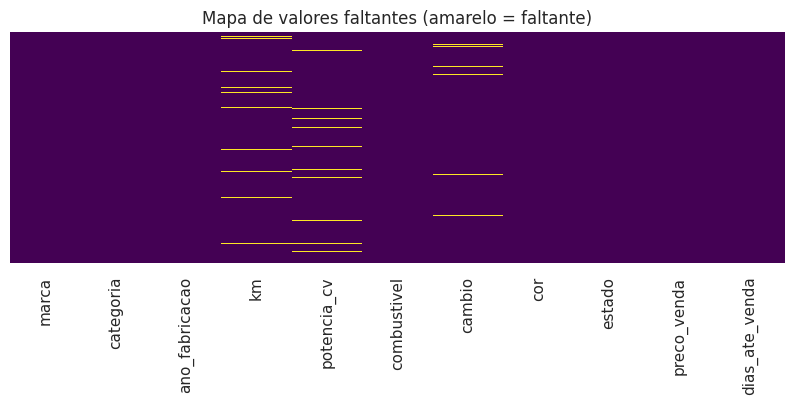

In [ ]:
print("Valores faltantes por coluna:")
print(df.isna().sum())
print("\nLinhas duplicadas:", df.duplicated().sum())

plt.figure(figsize=(10, 3))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Mapa de valores faltantes (amarelo = faltante)")
plt.show()

### 5.1 Distribuição do preço e outliers
O box plot e o histograma (com escala logarítmica) ajudam a achar valores fora da curva, como feito na aula 4.

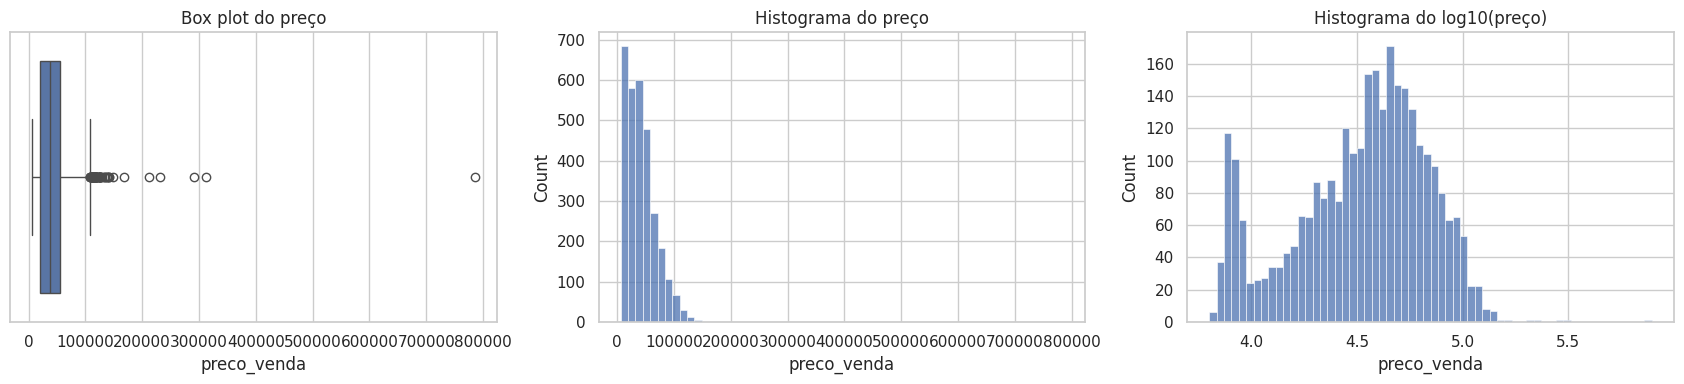

Maiores preços:
[785190. 312140. 290990. 231830. 211280. 168705. 149420. 141120. 140741.
 140280.]
Maiores km:
[999999. 999999. 999999. 999999. 306625. 305068. 292566. 291578.]


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.boxplot(x=df["preco_venda"], ax=ax[0]); ax[0].set_title("Box plot do preço")
sns.histplot(df["preco_venda"], bins=60, ax=ax[1]); ax[1].set_title("Histograma do preço")
sns.histplot(np.log10(df["preco_venda"]), bins=60, ax=ax[2]); ax[2].set_title("Histograma do log10(preço)")
plt.tight_layout(); plt.show()

print("Maiores preços:"); print(df["preco_venda"].nlargest(10).values)
print("Maiores km:"); print(df["km"].nlargest(8).values)

### 5.2 Variáveis categóricas

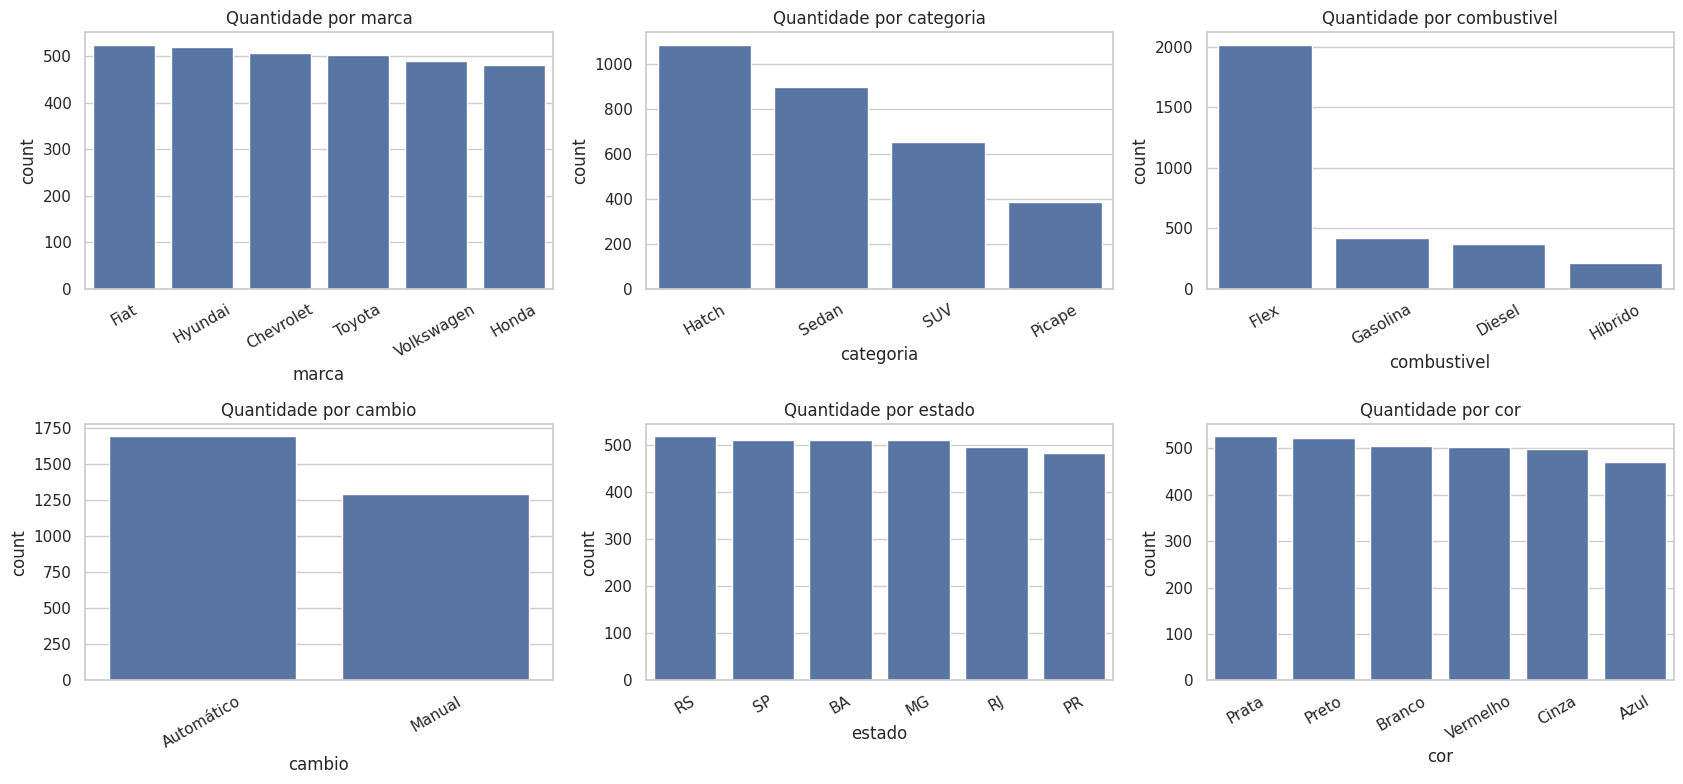

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for a, c in zip(ax.ravel(), ["marca", "categoria", "combustivel", "cambio", "estado", "cor"]):
    sns.countplot(data=df, x=c, order=df[c].value_counts().index, ax=a)
    a.set_title(f"Quantidade por {c}"); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

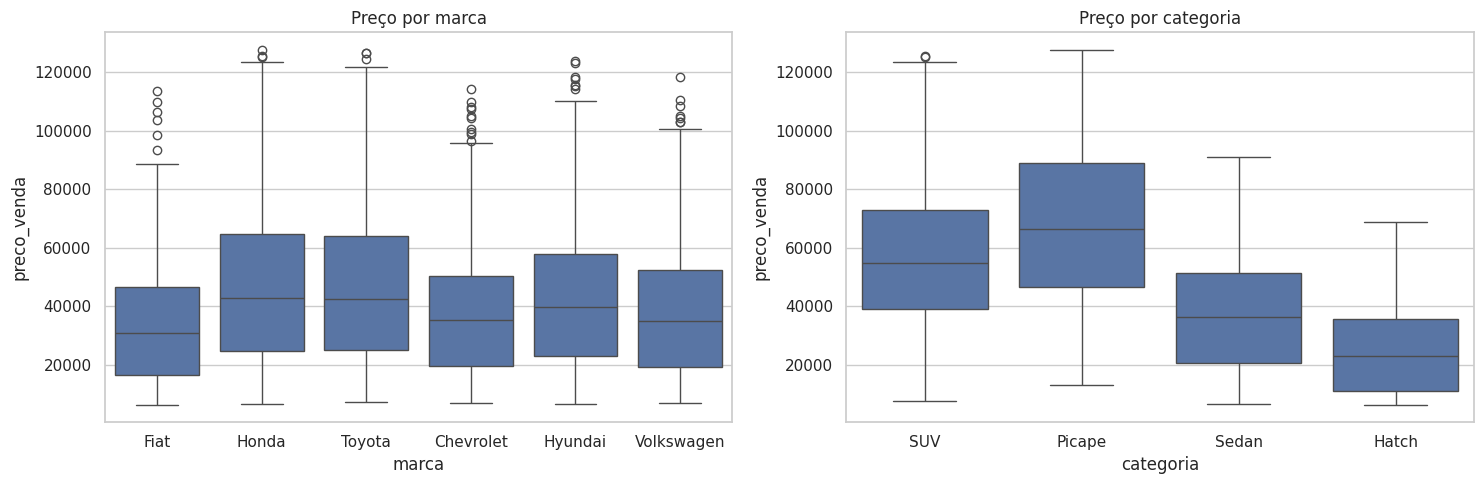

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df[df.preco_venda < df.preco_venda.quantile(0.995)], x="marca", y="preco_venda", ax=ax[0])
ax[0].set_title("Preço por marca")
sns.boxplot(data=df[df.preco_venda < df.preco_venda.quantile(0.995)], x="categoria", y="preco_venda", ax=ax[1])
ax[1].set_title("Preço por categoria")
plt.tight_layout(); plt.show()

## 6. Limpeza de dados
Decisões (cada trabalho exige uma justificativa):
- **Duplicados:** remover.
- **Outliers/erros de digitação:** remover km impossíveis (> 400.000) e preços fora de 3×IQR.
- **km e potência faltantes:** preencher pela **mediana** do grupo (categoria + ano), como foi feito com a idade no Titanic.
- **câmbio faltante:** poucas linhas, então remover.

In [ ]:
n0 = len(df)
dfc = df.drop_duplicates().copy()
dfc = dfc[(dfc["km"].isna()) | (dfc["km"] <= 400000)]

q1, q3 = dfc["preco_venda"].quantile([0.25, 0.75])
lim_sup = q3 + 3 * (q3 - q1)
dfc = dfc[dfc["preco_venda"] <= lim_sup]

for col in ["km", "potencia_cv"]:
    dfc[col] = dfc[col].fillna(dfc.groupby(["categoria", "ano_fabricacao"])[col].transform("median"))
    dfc[col] = dfc[col].fillna(dfc[col].median())

dfc = dfc.dropna(subset=["cambio"]).reset_index(drop=True)
print(f"Linhas antes: {n0} | depois: {len(dfc)}")
print("Faltantes restantes:", int(dfc.isna().sum().sum()))

Linhas antes: 3025 | depois: 2950
Faltantes restantes: 0


## 7. Engenharia de dados
Computador entende número, não palavra. Criamos a idade e o alvo de classificação, e transformamos categorias em colunas numéricas (`get_dummies`, removendo uma coluna por variável).

In [ ]:
dfc["idade"] = 2026 - dfc["ano_fabricacao"]
dfc["vendido_rapido"] = (dfc["dias_ate_venda"] <= 30).astype(int)
print("Balanceamento do alvo de classificação:")
print(dfc["vendido_rapido"].value_counts(normalize=True).round(3))

cats = ["marca", "categoria", "combustivel", "cambio", "estado", "cor"]
dados = pd.get_dummies(dfc.drop(columns=["ano_fabricacao"]), columns=cats, drop_first=True, dtype=int)
dados.head()

Balanceamento do alvo de classificação:
vendido_rapido
0    0.651
1    0.349
Name: proportion, dtype: float64


,km,potencia_cv,preco_venda,dias_ate_venda,idade,vendido_rapido,marca_Fiat,marca_Honda,marca_Hyundai,marca_Toyota,...,estado_MG,estado_PR,estado_RJ,estado_RS,estado_SP,cor_Branco,cor_Cinza,cor_Prata,cor_Preto,cor_Vermelho
0,73437.0,150.0,53782.0,45.0,8,0,1,0,0,0,...,0,0,0,1,0,0,0,0,1,0
1,201066.0,182.0,39022.0,26.0,14,1,0,1,0,0,...,0,0,1,0,0,0,0,0,1,0
2,62558.0,148.0,57374.0,50.0,5,0,0,0,0,1,...,0,0,0,0,1,0,0,1,0,0
3,57728.0,124.0,35298.0,31.0,8,0,0,0,0,0,...,1,0,0,0,0,0,0,1,0,0
4,53565.0,176.0,68603.0,12.0,4,1,0,0,0,0,...,0,1,0,0,0,0,0,1,0,0


## 8. Correlação
Queremos correlação **alta com o alvo** (preço) e **baixa entre as variáveis independentes** (multicolinearidade), como explicado na aula 6.

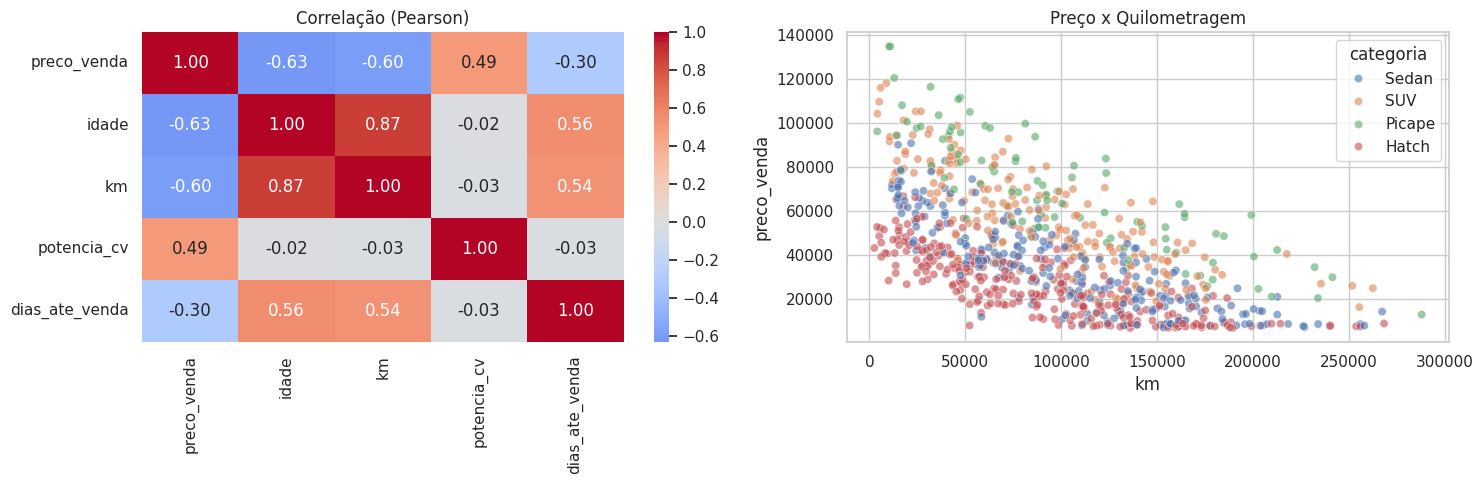

preco_venda       1.000
potencia_cv       0.490
dias_ate_venda   -0.297
km               -0.600
idade            -0.634
Name: preco_venda, dtype: float64


In [ ]:
num = ["preco_venda", "idade", "km", "potencia_cv", "dias_ate_venda"]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(dfc[num].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[0])
ax[0].set_title("Correlação (Pearson)")
sns.scatterplot(data=dfc.sample(800, random_state=1), x="km", y="preco_venda", hue="categoria", alpha=0.6, ax=ax[1])
ax[1].set_title("Preço x Quilometragem")
plt.tight_layout(); plt.show()
print(dfc[num].corr()["preco_venda"].sort_values(ascending=False).round(3))

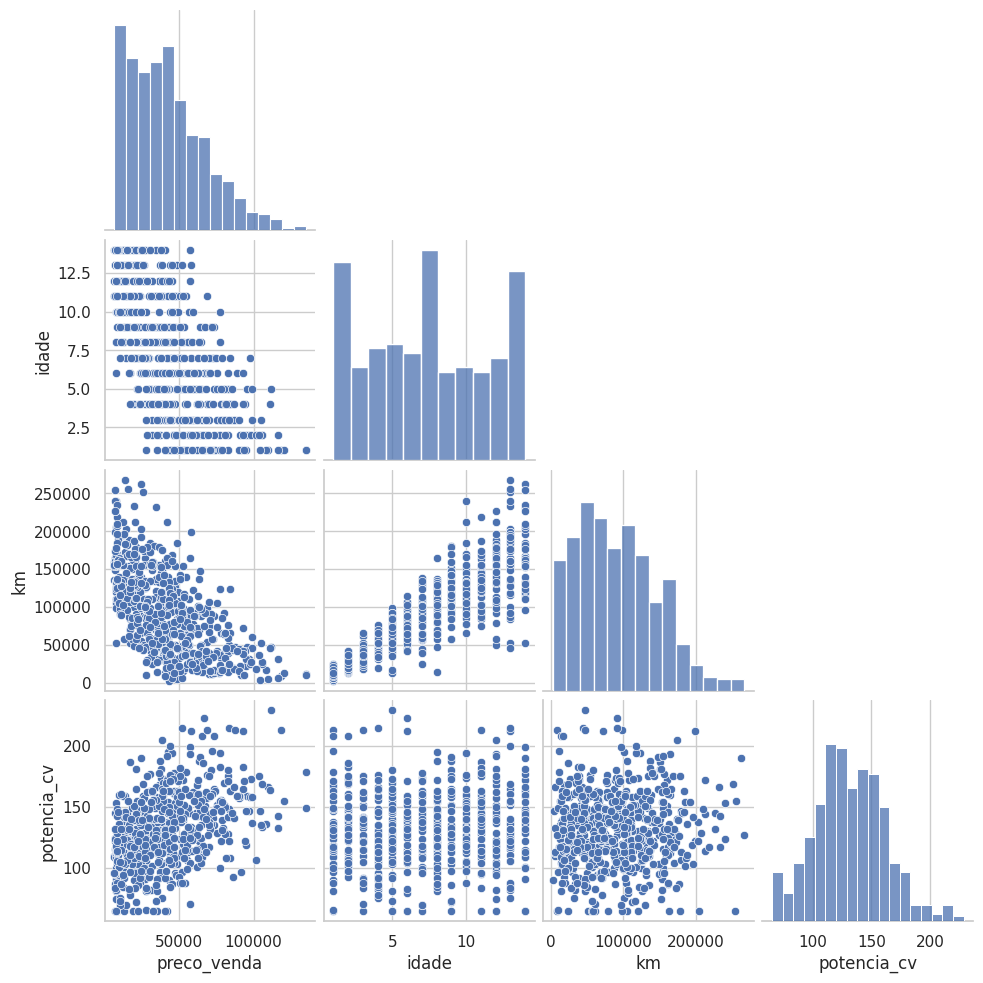

In [ ]:
sns.pairplot(dfc[["preco_venda", "idade", "km", "potencia_cv"]].sample(600, random_state=1), corner=True)
plt.show()

**Leitura:** `idade` e `km` são fortemente correlacionadas entre si (carro mais velho roda mais). Isso é multicolinearidade e afeta a interpretação dos coeficientes da regressão — vamos manter as duas e comentar isso na conclusão (ou teste removendo uma e compare o R²).

## 9. Regressão linear — prever o preço de venda
**Tipo de regressão:** regressão linear múltipla (aprendizado supervisionado, alvo contínuo). Divisão 80% treino / 20% teste, com embaralhamento e `random_state` fixo.

In [ ]:
X = dados.drop(columns=["preco_venda", "dias_ate_venda", "vendido_rapido"])
y = dados["preco_venda"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=RANDOM_STATE)
print("Treino:", X_tr.shape, "| Teste:", X_te.shape)

lm = LinearRegression()
lm.fit(X_tr, y_tr)
pred_tr, pred_te = lm.predict(X_tr), lm.predict(X_te)

coef = pd.Series(lm.coef_, index=X.columns).sort_values()
print("Intercepto:", round(lm.intercept_, 2))
coef.round(2).to_frame("coeficiente (R$)")

Treino: (2360, 25) | Teste: (590, 25)
Intercepto: 37234.78


,coeficiente (R$)
combustivel_Flex,-5507.57
combustivel_Gasolina,-5470.67
cambio_Manual,-4128.49
idade,-3219.39
marca_Fiat,-936.52
estado_PR,-806.53
cor_Prata,-710.18
estado_SP,-665.74
estado_MG,-590.36
cor_Branco,-510.13


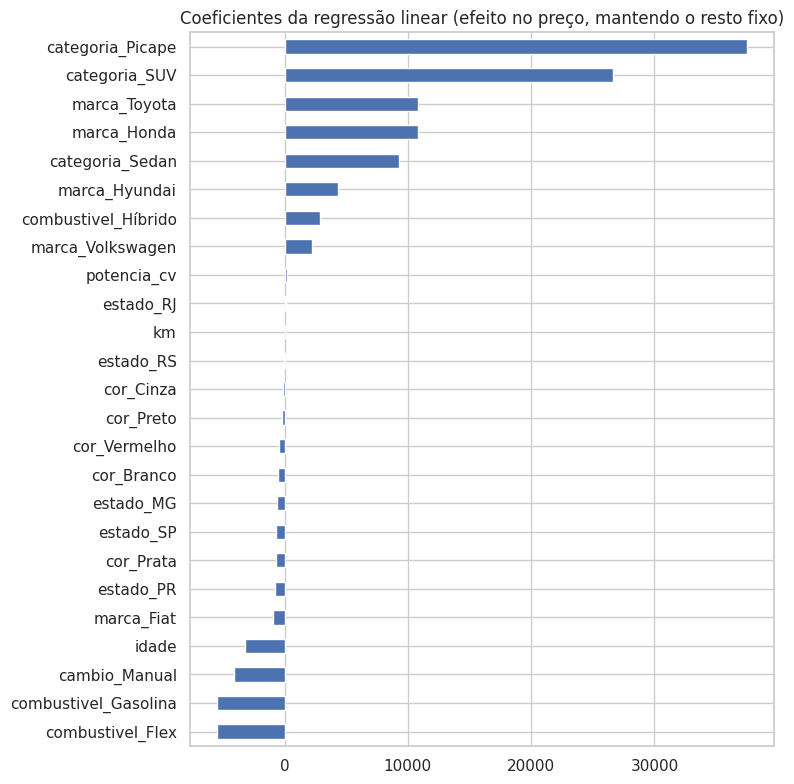

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))
coef.plot(kind="barh", ax=ax); ax.set_title("Coeficientes da regressão linear (efeito no preço, mantendo o resto fixo)")
plt.tight_layout(); plt.show()

### 9.1 Precisão do modelo de regressão (MAE, MSE, RMSE, R²)

In [ ]:
def metricas_reg(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mae, "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}

res_reg = pd.DataFrame({"Treino": metricas_reg(y_tr, pred_tr), "Teste": metricas_reg(y_te, pred_te)}).round(3)
res_reg

,Treino,Teste
MAE,5.978505e+03,6.288790e+03
MSE,6.289004e+07,9.083088e+07
RMSE,7.930324e+03,9.530524e+03
R2,9.080000e-01,8.610000e-01


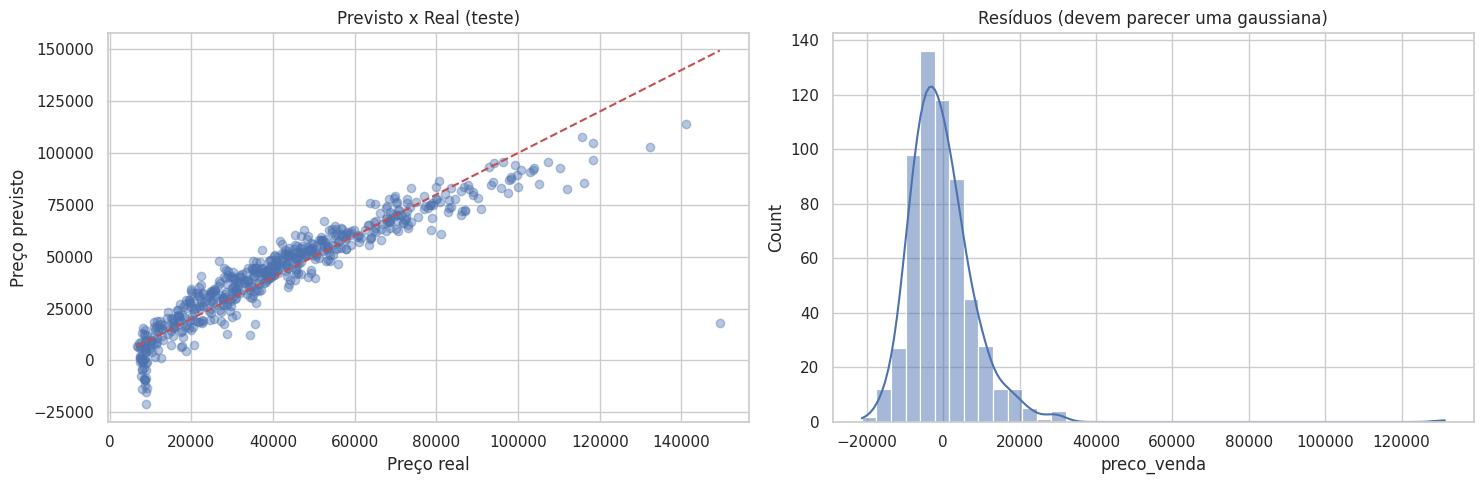

Erro típico (RMSE): R$ 9,531


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].scatter(y_te, pred_te, alpha=0.4)
lim = [y_te.min(), y_te.max()]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Preço real"); ax[0].set_ylabel("Preço previsto")
ax[0].set_title("Previsto x Real (teste)")
residuo = y_te - pred_te
sns.histplot(residuo, kde=True, bins=40, ax=ax[1]); ax[1].set_title("Resíduos (devem parecer uma gaussiana)")
plt.tight_layout(); plt.show()
print(f"Erro típico (RMSE): R$ {np.sqrt(mean_squared_error(y_te, pred_te)):,.0f}")

**Como interpretar:** se os resíduos formam um sino centrado em zero, o modelo está bem comportado. O RMSE penaliza erros grandes (por causa do quadrado) e é o erro típico em R$. Compare Treino x Teste: valores parecidos indicam que **não há overfitting**.

## 10. Classificação — prever se o veículo vende em até 30 dias
Alvo: `vendido_rapido` (1 = vende em ≤ 30 dias). Passos das aulas: separar treino/teste, **padronizar** (necessário para regressão logística e KNN), treinar, avaliar com `classification_report` e matriz de confusão.

In [ ]:
Xc = dados.drop(columns=["preco_venda", "dias_ate_venda", "vendido_rapido"])
# Importante: dias_ate_venda é removida (vazaria a resposta). O preço entra como variável explicativa.
Xc["preco_venda"] = dados["preco_venda"]
yc = dados["vendido_rapido"]

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.2, shuffle=True,
                                              random_state=RANDOM_STATE, stratify=yc)
scaler = StandardScaler().fit(Xc_tr)
Xc_tr_s, Xc_te_s = scaler.transform(Xc_tr), scaler.transform(Xc_te)

def avaliar(nome, modelo, usa_escala=False):
    a, b = (Xc_tr_s, Xc_te_s) if usa_escala else (Xc_tr, Xc_te)
    modelo.fit(a, yc_tr)
    p_tr, p_te = modelo.predict(a), modelo.predict(b)
    rep = classification_report(yc_te, p_te, output_dict=True)
    return {"modelo": nome,
            "acurácia treino": (p_tr == yc_tr).mean(),
            "acurácia teste": (p_te == yc_te).mean(),
            "precisão (classe 1)": rep["1"]["precision"],
            "recall (classe 1)": rep["1"]["recall"],
            "F1 (classe 1)": rep["1"]["f1-score"]}, p_te

### 10.1 Regressão logística (modelo base)

               precision    recall  f1-score   support

 lento (>30d)       0.84      0.70      0.76       384
rápido (≤30d)       0.57      0.75      0.65       206

     accuracy                           0.71       590
    macro avg       0.70      0.72      0.70       590
 weighted avg       0.74      0.71      0.72       590



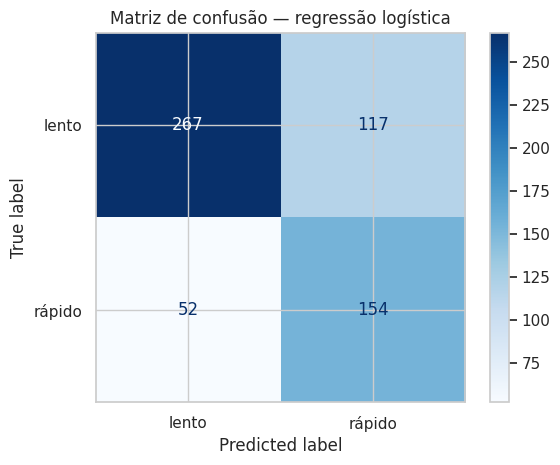

In [ ]:
log = LogisticRegression(max_iter=1000, class_weight="balanced")
r_log, p_log = avaliar("Regressão logística", log, usa_escala=True)
print(classification_report(yc_te, p_log, target_names=["lento (>30d)", "rápido (≤30d)"]))
ConfusionMatrixDisplay(confusion_matrix(yc_te, p_log), display_labels=["lento", "rápido"]).plot(cmap="Blues")
plt.title("Matriz de confusão — regressão logística"); plt.show()

### 10.2 K vizinhos mais próximos (KNN)
O hiperparâmetro K é escolhido olhando o erro de treino e de teste (curva da aula 6).

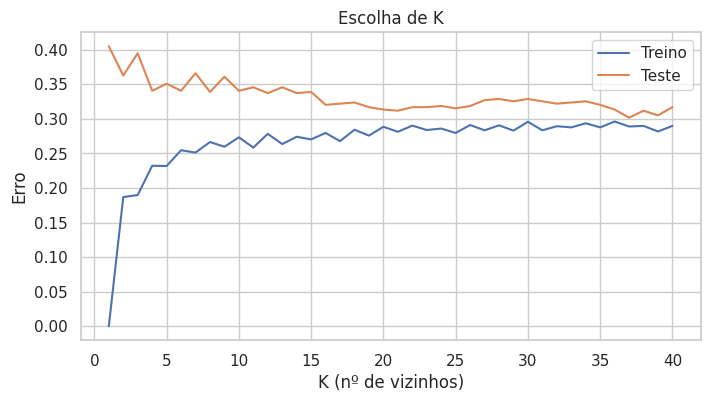

Melhor K: 37


In [ ]:
ks = range(1, 41)
err_tr, err_te = [], []
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k).fit(Xc_tr_s, yc_tr)
    err_tr.append(1 - m.score(Xc_tr_s, yc_tr)); err_te.append(1 - m.score(Xc_te_s, yc_te))
plt.figure(figsize=(8, 4))
plt.plot(ks, err_tr, label="Treino"); plt.plot(ks, err_te, label="Teste")
plt.xlabel("K (nº de vizinhos)"); plt.ylabel("Erro"); plt.legend(); plt.title("Escolha de K")
plt.show()
k_best = ks[int(np.argmin(err_te))]
print("Melhor K:", k_best)
r_knn, p_knn = avaliar(f"KNN (k={k_best})", KNeighborsClassifier(n_neighbors=k_best), usa_escala=True)

### 10.3 Árvore de decisão
Sem limite de profundidade a árvore decora o treino (overfitting). Comparamos profundidades.

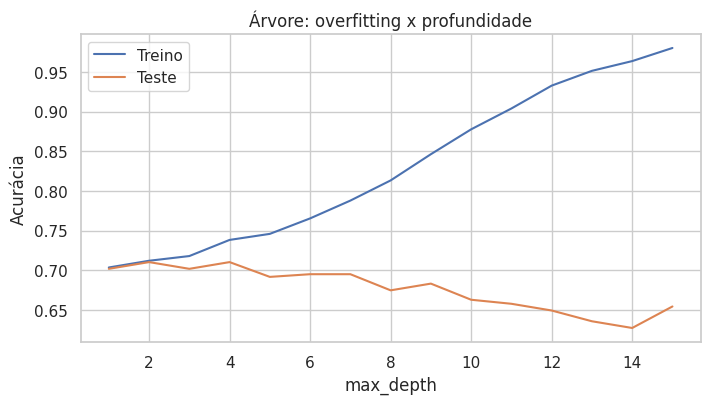

Melhor profundidade: 2


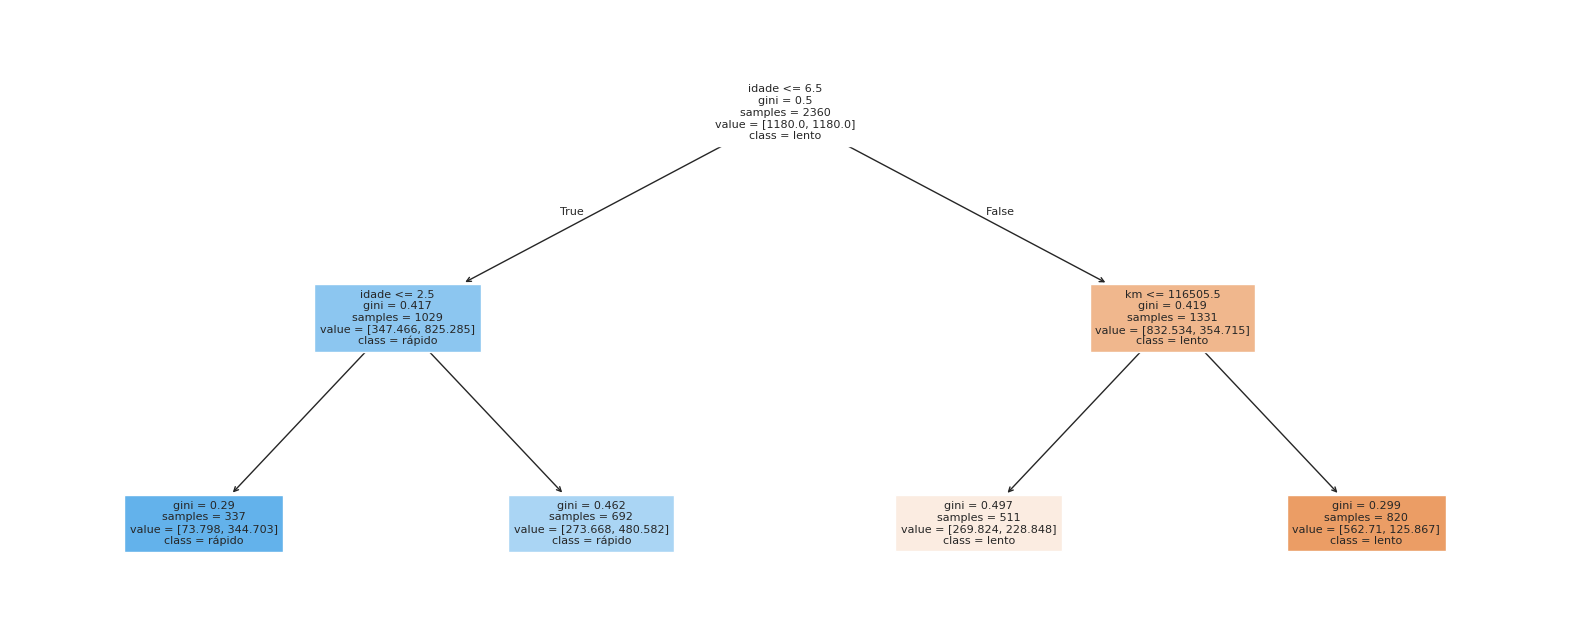

In [ ]:
prof = range(1, 16)
a_tr, a_te = [], []
for d in prof:
    t = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(Xc_tr, yc_tr)
    a_tr.append(t.score(Xc_tr, yc_tr)); a_te.append(t.score(Xc_te, yc_te))
plt.figure(figsize=(8, 4))
plt.plot(prof, a_tr, label="Treino"); plt.plot(prof, a_te, label="Teste")
plt.xlabel("max_depth"); plt.ylabel("Acurácia"); plt.legend(); plt.title("Árvore: overfitting x profundidade")
plt.show()
d_best = prof[int(np.argmax(a_te))]
print("Melhor profundidade:", d_best)
arvore = DecisionTreeClassifier(max_depth=min(d_best, 4), class_weight="balanced", random_state=RANDOM_STATE)
r_arv, p_arv = avaliar(f"Árvore (depth={min(d_best,4)})", arvore)
plt.figure(figsize=(20, 8))
plot_tree(arvore, feature_names=Xc.columns, class_names=["lento", "rápido"], filled=True, fontsize=8, max_depth=3)
plt.show()

### 10.4 Random Forest (bagging) com busca de hiperparâmetros

Melhores hiperparâmetros: {'max_depth': 6, 'max_features': 'sqrt', 'n_estimators': 100}


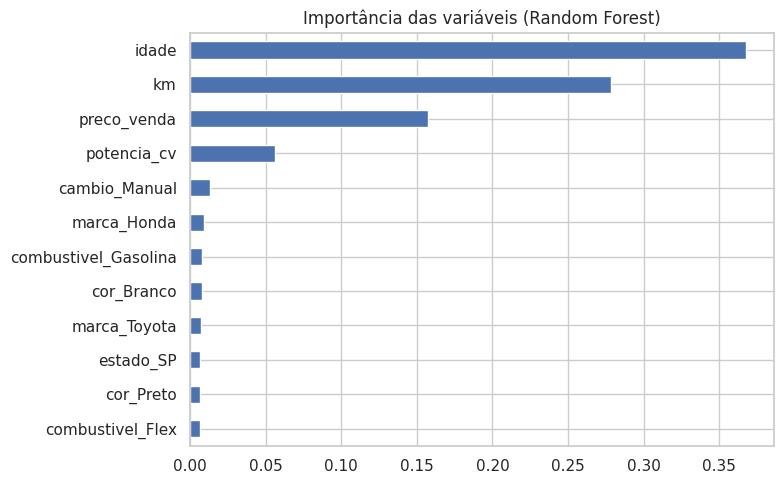

In [ ]:
grid = {"n_estimators": [100, 200], "max_depth": [6, 10, None], "max_features": ["sqrt", "log2"]}
gs = GridSearchCV(RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
                  grid, cv=3, scoring="f1", n_jobs=-1)
gs.fit(Xc_tr, yc_tr)
print("Melhores hiperparâmetros:", gs.best_params_)
r_rf, p_rf = avaliar("Random Forest (grid)", gs.best_estimator_)
imp = pd.Series(gs.best_estimator_.feature_importances_, index=Xc.columns).sort_values(ascending=False).head(12)
plt.figure(figsize=(8, 5)); imp.sort_values().plot(kind="barh"); plt.title("Importância das variáveis (Random Forest)")
plt.tight_layout(); plt.show()

### 10.5 Gradient Boosting (boosting)

In [ ]:
gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE)
r_gb, p_gb = avaliar("Gradient Boosting", gb)

## 11. Comparação final dos modelos

,acurácia treino,acurácia teste,precisão (classe 1),recall (classe 1),F1 (classe 1),gap treino-teste
modelo,,,,,,
Regressão logística,0.734,0.714,0.568,0.748,0.646,0.020
KNN (k=37),0.711,0.698,0.637,0.316,0.422,0.013
Árvore (depth=2),0.703,0.702,0.560,0.684,0.616,0.001
Random Forest (grid),0.734,0.676,0.527,0.704,0.603,0.058
Gradient Boosting,0.807,0.731,0.654,0.485,0.557,0.076


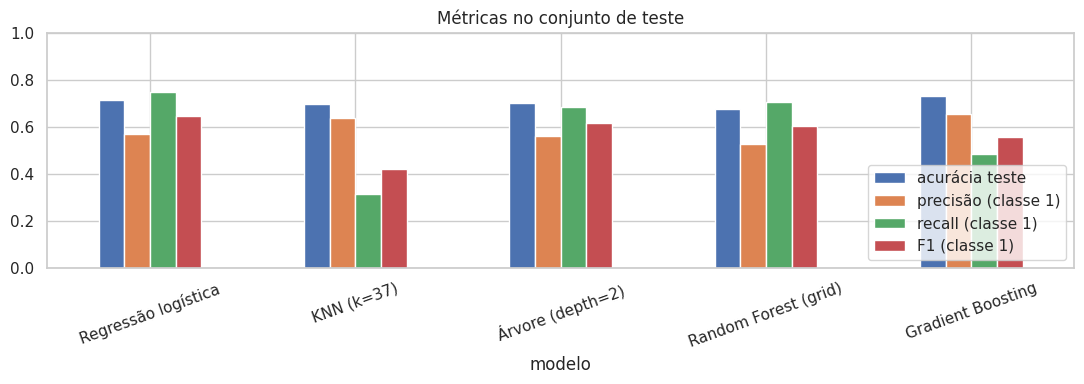

Melhor modelo por F1: Regressão logística


In [ ]:
comp = pd.DataFrame([r_log, r_knn, r_arv, r_rf, r_gb]).set_index("modelo").round(3)
comp["gap treino-teste"] = (comp["acurácia treino"] - comp["acurácia teste"]).round(3)
display(comp)

comp[["acurácia teste", "precisão (classe 1)", "recall (classe 1)", "F1 (classe 1)"]].plot(kind="bar", figsize=(11, 4))
plt.ylim(0, 1); plt.title("Métricas no conjunto de teste"); plt.xticks(rotation=20); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

melhor = comp["F1 (classe 1)"].idxmax()
cm = confusion_matrix(yc_te, {"Regressão logística": p_log, "KNN": p_knn}.get(melhor, p_rf if "Forest" in melhor else (p_gb if "Gradient" in melhor else p_arv)))
print("Melhor modelo por F1:", melhor)

## 12. Perguntas extras de negócio

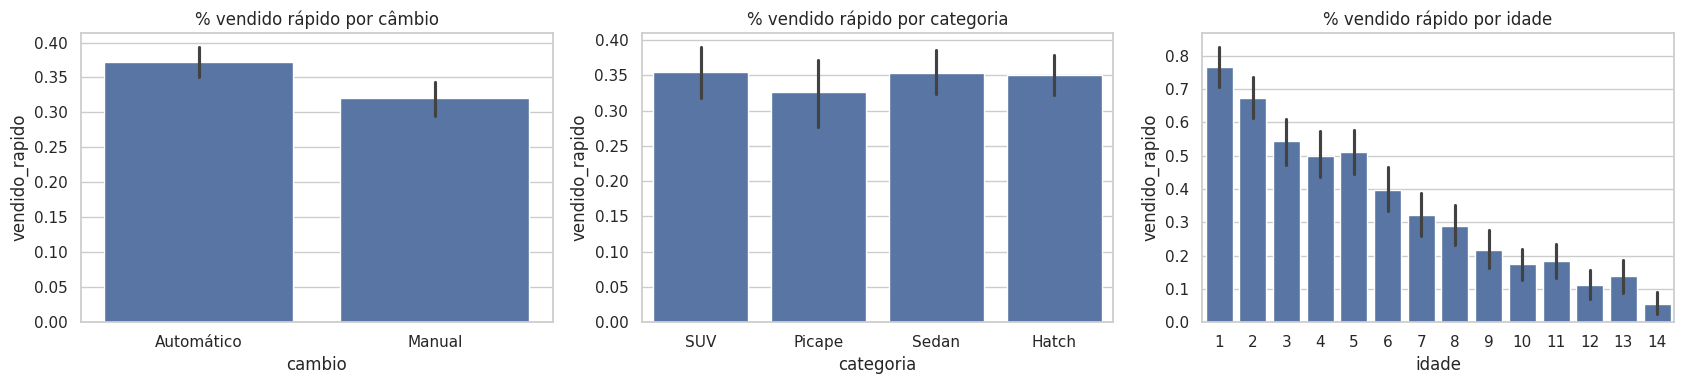

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.barplot(data=dfc, x="cambio", y="vendido_rapido", ax=ax[0]); ax[0].set_title("% vendido rápido por câmbio")
sns.barplot(data=dfc, x="categoria", y="vendido_rapido", ax=ax[1]); ax[1].set_title("% vendido rápido por categoria")
sns.barplot(data=dfc, x="idade", y="vendido_rapido", ax=ax[2]); ax[2].set_title("% vendido rápido por idade")
plt.tight_layout(); plt.show()

## 13. Conclusões (respostas às perguntas)
Os números abaixo são calculados automaticamente a partir dos resultados.

In [ ]:
corr = dfc[["preco_venda", "idade", "km", "potencia_cv"]].corr()["preco_venda"]
rmse = np.sqrt(mean_squared_error(y_te, pred_te))
top_coef = coef.abs().sort_values(ascending=False).head(3).index.tolist()
top_imp = imp.head(3).index.tolist()

print(f'''
1) Variáveis que mais influenciam o preço (maiores |coeficientes|): {top_coef}.
2) Correlação com o preço: idade = {corr["idade"]:.2f}, km = {corr["km"]:.2f}, potência = {corr["potencia_cv"]:.2f}.
   idade e km são correlacionadas entre si ({dfc["idade"].corr(dfc["km"]):.2f}) -> multicolinearidade.
3) Qualidade dos dados: {n0 - len(dfc)} linhas removidas (duplicados, km impossível, preços absurdos);
   faltantes de km/potência preenchidos pela mediana do grupo.
4) Regressão linear: R² teste = {r2_score(y_te, pred_te):.3f}; erro típico (RMSE) = R$ {rmse:,.0f};
   R² treino = {r2_score(y_tr, pred_tr):.3f} (diferença pequena -> overfitting leve ou ausente).
5) Classificação (vender em ≤30 dias): melhor modelo = {melhor}
   com F1 = {comp.loc[melhor, "F1 (classe 1)"]:.3f} e acurácia teste = {comp.loc[melhor, "acurácia teste"]:.3f}.
6) Variáveis mais importantes para vender rápido (Random Forest): {top_imp}.
7) Overfitting: veja a coluna "gap treino-teste" — quanto maior, mais o modelo decorou o treino.
8) Modelos mais sofisticados só valem a pena se superarem claramente o modelo simples (logística)
   em F1 no teste; caso contrário, prefira o mais explicável.
''')


1) Variáveis que mais influenciam o preço (maiores |coeficientes|): ['categoria_Picape', 'categoria_SUV', 'marca_Toyota'].
2) Correlação com o preço: idade = -0.63, km = -0.60, potência = 0.49.
   idade e km são correlacionadas entre si (0.87) -> multicolinearidade.
3) Qualidade dos dados: 75 linhas removidas (duplicados, km impossível, preços absurdos);
   faltantes de km/potência preenchidos pela mediana do grupo.
4) Regressão linear: R² teste = 0.861; erro típico (RMSE) = R$ 9,531;
   R² treino = 0.908 (diferença pequena -> overfitting leve ou ausente).
5) Classificação (vender em ≤30 dias): melhor modelo = Regressão logística
   com F1 = 0.646 e acurácia teste = 0.714.
6) Variáveis mais importantes para vender rápido (Random Forest): ['idade', 'km', 'preco_venda'].
7) Overfitting: veja a coluna "gap treino-teste" — quanto maior, mais o modelo decorou o treino.
8) Modelos mais sofisticados só valem a pena se superarem claramente o modelo simples (logística)
   em F1 no teste; caso 

### Resumo visual das respostas
Um gráfico para cada pergunta do projeto (os números do texto acima aparecem aqui em forma visual).

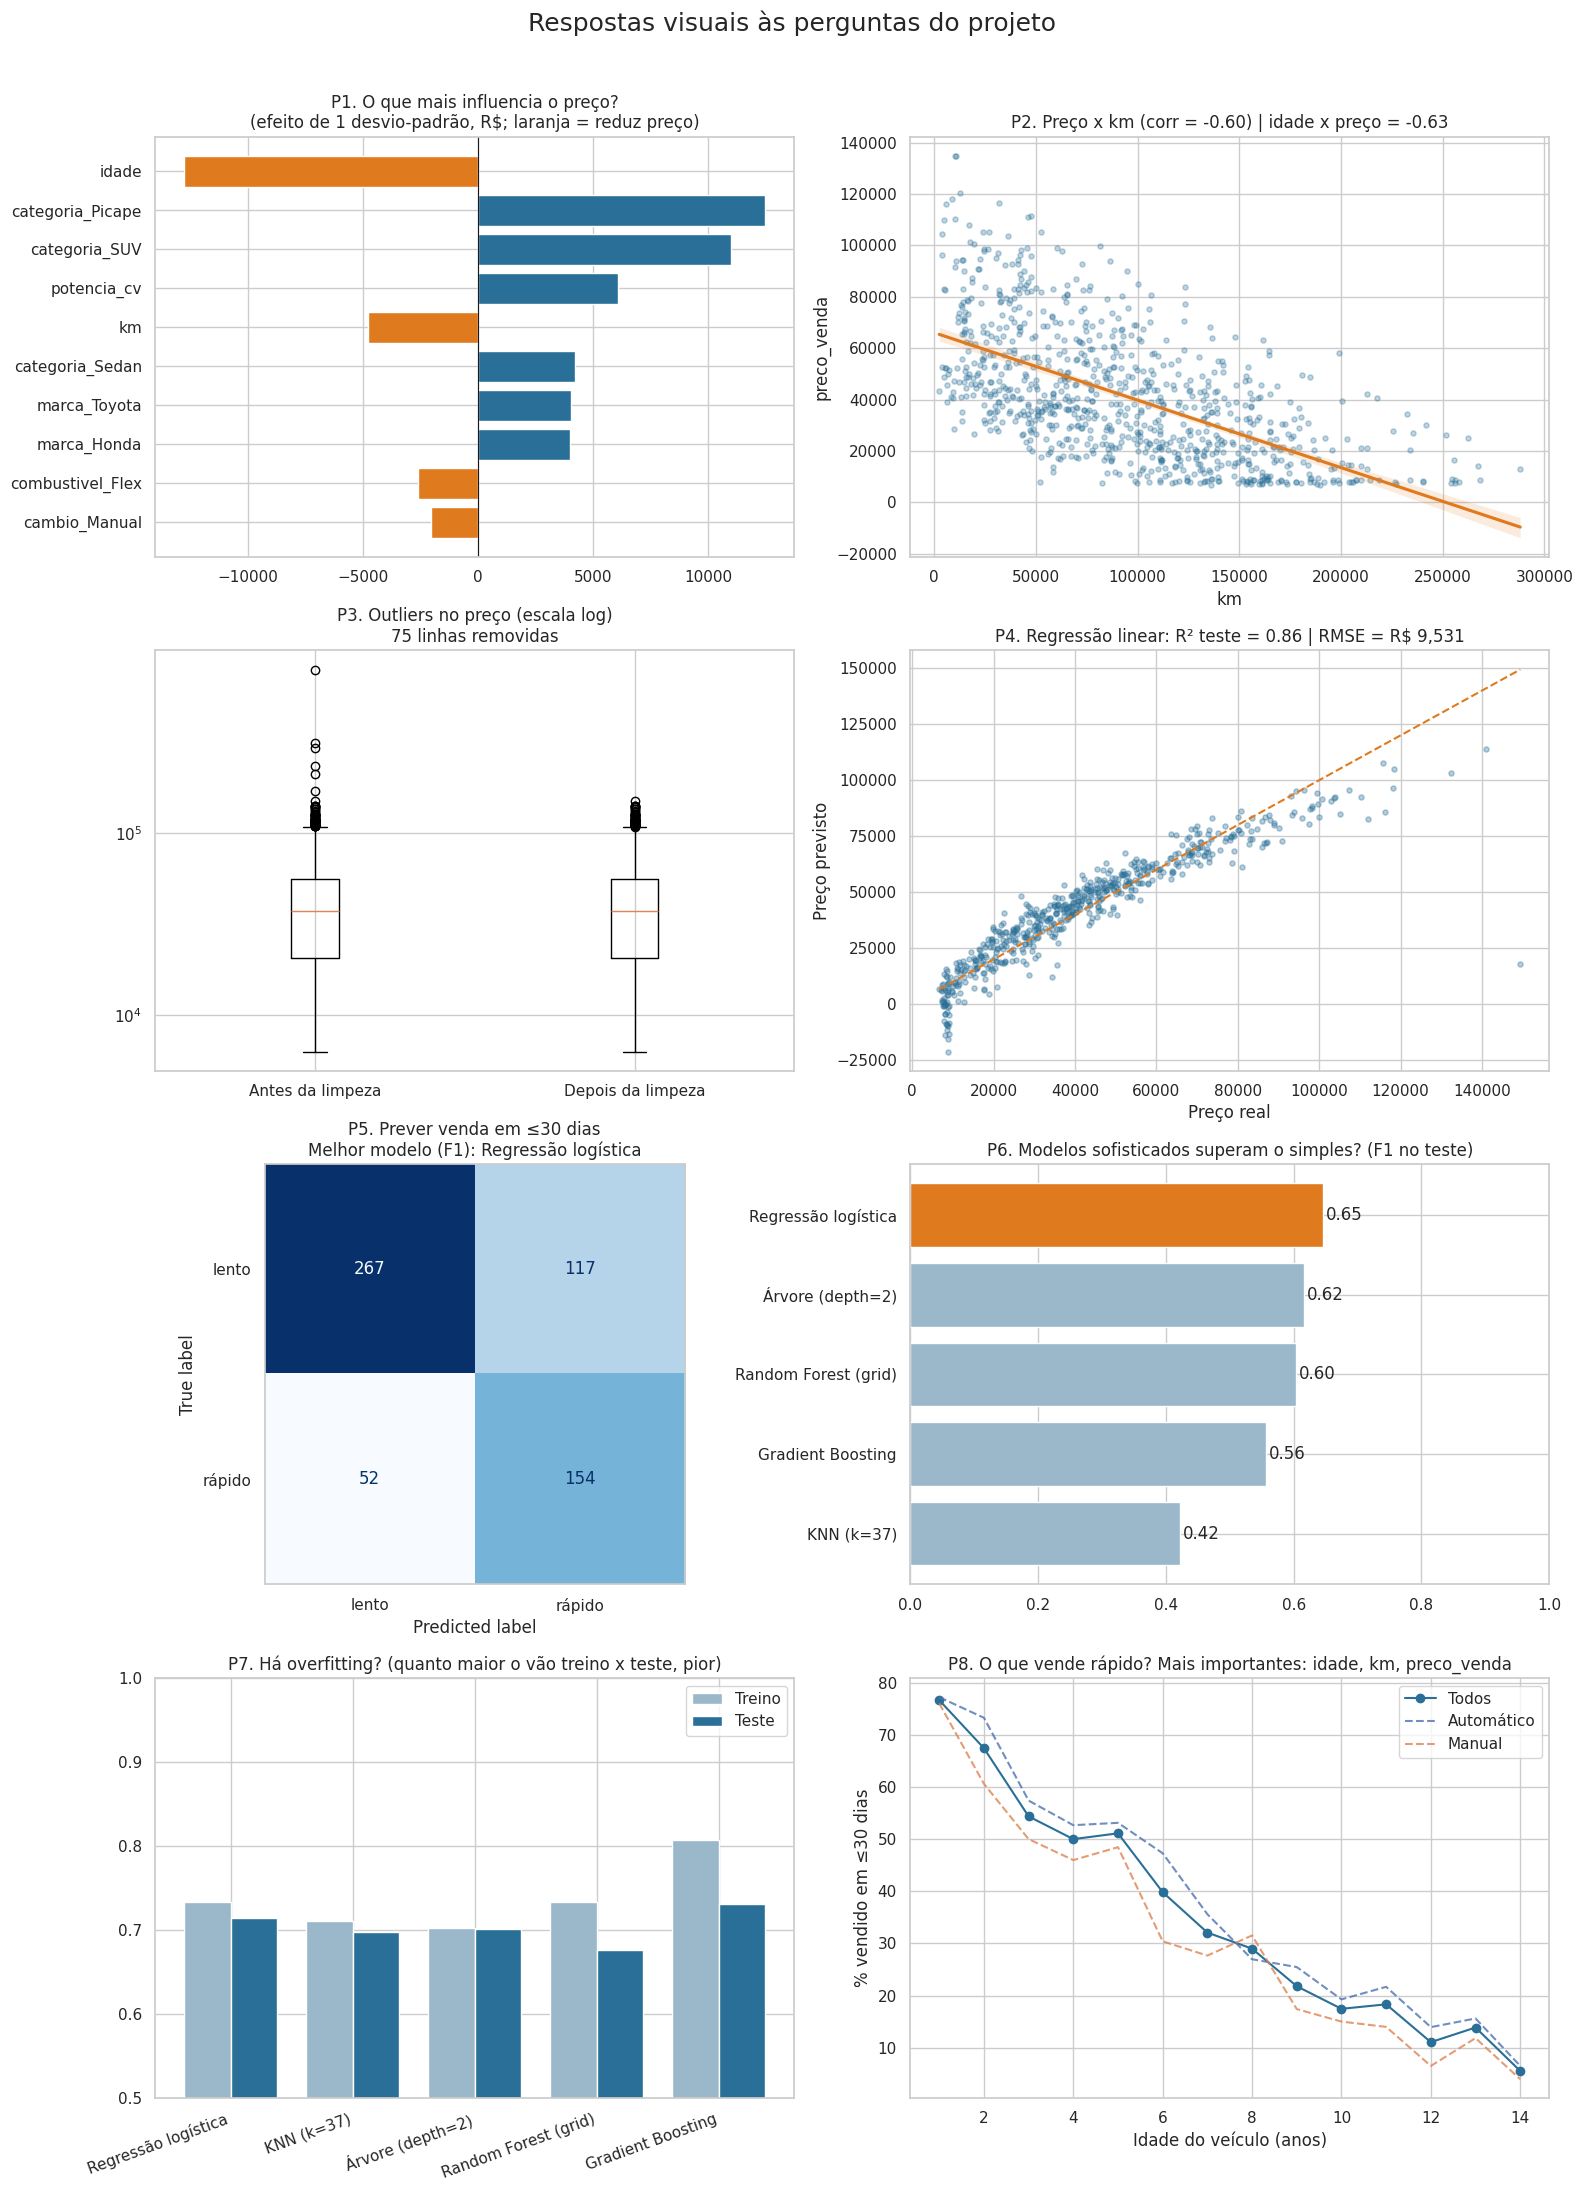

In [ ]:
preds = {r_log["modelo"]: p_log, r_knn["modelo"]: p_knn, r_arv["modelo"]: p_arv,
         r_rf["modelo"]: p_rf, r_gb["modelo"]: p_gb}
cor_main, cor_alt, cor_dest = "#2a6f97", "#9ab8c9", "#e07a1f"

fig, axes = plt.subplots(4, 2, figsize=(16, 22))
fig.suptitle("Respostas visuais às perguntas do projeto", fontsize=18, y=0.995)

# P1 - variáveis que mais influenciam o preço (coeficientes padronizados)
ax = axes[0, 0]
coef_pad = (pd.Series(lm.coef_, index=X.columns) * X_tr.std()).sort_values(key=abs, ascending=False).head(10)[::-1]
ax.barh(coef_pad.index, coef_pad.values, color=[cor_main if v > 0 else cor_dest for v in coef_pad.values])
ax.axvline(0, color="k", lw=0.8)
ax.set_title("P1. O que mais influencia o preço?\n(efeito de 1 desvio-padrão, R$; laranja = reduz preço)")

# P2 - idade e km x preço
ax = axes[0, 1]
amostra = dfc.sample(900, random_state=1)
sns.regplot(data=amostra, x="km", y="preco_venda", scatter_kws={"alpha": 0.3, "s": 14}, line_kws={"color": cor_dest}, ax=ax, color=cor_main)
ax.set_title(f"P2. Preço x km (corr = {dfc['km'].corr(dfc['preco_venda']):.2f}) | "
             f"idade x preço = {dfc['idade'].corr(dfc['preco_venda']):.2f}")

# P3 - outliers antes e depois da limpeza
ax = axes[1, 0]
ax.boxplot([df["preco_venda"].dropna(), dfc["preco_venda"]], showfliers=True)
ax.set_xticklabels(["Antes da limpeza", "Depois da limpeza"])
ax.set_yscale("log")
ax.set_title(f"P3. Outliers no preço (escala log)\n{n0 - len(dfc)} linhas removidas")

# P4 - previsto x real
ax = axes[1, 1]
ax.scatter(y_te, pred_te, alpha=0.35, s=14, color=cor_main)
lim = [y_te.min(), y_te.max()]
ax.plot(lim, lim, "--", color=cor_dest)
ax.set_xlabel("Preço real"); ax.set_ylabel("Preço previsto")
ax.set_title(f"P4. Regressão linear: R² teste = {r2_score(y_te, pred_te):.2f} | RMSE = R$ {rmse:,.0f}")

# P5 - matriz de confusão do melhor modelo
ax = axes[2, 0]
ConfusionMatrixDisplay(confusion_matrix(yc_te, preds[melhor]), display_labels=["lento", "rápido"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.grid(False)
ax.set_title(f"P5. Prever venda em ≤30 dias\nMelhor modelo (F1): {melhor}")

# P6 - F1 por modelo
ax = axes[2, 1]
f1 = comp["F1 (classe 1)"].sort_values()
ax.barh(f1.index, f1.values, color=[cor_dest if m == melhor else cor_alt for m in f1.index])
for i, v in enumerate(f1.values):
    ax.text(v + 0.005, i, f"{v:.2f}", va="center")
ax.set_xlim(0, 1)
ax.set_title("P6. Modelos sofisticados superam o simples? (F1 no teste)")

# P7 - overfitting: treino x teste
ax = axes[3, 0]
x = np.arange(len(comp)); w = 0.38
ax.bar(x - w/2, comp["acurácia treino"], w, label="Treino", color=cor_alt)
ax.bar(x + w/2, comp["acurácia teste"], w, label="Teste", color=cor_main)
ax.set_xticks(x); ax.set_xticklabels(comp.index, rotation=20, ha="right")
ax.set_ylim(0.5, 1); ax.legend()
ax.set_title("P7. Há overfitting? (quanto maior o vão treino x teste, pior)")

# P8 - o que faz vender rápido
ax = axes[3, 1]
taxa = dfc.groupby("idade")["vendido_rapido"].mean() * 100
ax.plot(taxa.index, taxa.values, marker="o", color=cor_main, label="Todos")
for c_ in ["Automático", "Manual"]:
    t = dfc[dfc["cambio"] == c_].groupby("idade")["vendido_rapido"].mean() * 100
    ax.plot(t.index, t.values, ls="--", alpha=0.8, label=c_)
ax.set_xlabel("Idade do veículo (anos)"); ax.set_ylabel("% vendido em ≤30 dias")
ax.legend()
ax.set_title(f"P8. O que vende rápido? Mais importantes: {', '.join(top_imp)}")

plt.tight_layout(rect=[0, 0, 1, 0.985])
plt.show()

### Limitações e próximos passos
- Dados sintéticos: relações foram programadas; com dados reais os resultados serão menos limpos.
- O alvo de venda rápida depende do preço anunciado; em dados reais convém comparar o preço com o valor de mercado (ex.: tabela FIPE).
- Possíveis extensões: ajustar hiperparâmetros com Optuna, tratar desbalanceamento (SMOTE) e testar XGBoost/LightGBM.
- Mantenha um conjunto final de dados nunca visto (≈10%) para a "prova final" do modelo.